<a href="https://colab.research.google.com/github/kilakill010-commits/Fuzzy2/blob/main/AI_Smart_Trafic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  SIMULASI PROSEDURAL SMART TRAFFIC LIGHT (TANPA LIBRARY FUZZY/CV)

[TAHAP 1: AKUISISI SENSORIK KAMERA & PARAMETER LINGKUNGAN]
- Intensitas Cahaya (Lux)  : 254.9 Lux (Threshold Biner Adaptif = 30)
- Jalur Utara  : Piksel =  8400/12000 | Kepadatan =  70.0% | Est. Mobil = 7 unit | Kec. =  8.1 km/jam <-- FASE AKTIF
- Jalur Timur  : Piksel =  3600/12000 | Kepadatan =  30.0% | Est. Mobil = 3 unit | Kec. = 24.3 km/jam
- Jalur Selatan: Piksel =  1800/12000 | Kepadatan =  15.0% | Est. Mobil = 2 unit | Kec. = 32.4 km/jam
- Jalur Barat  : Piksel =  2400/12000 | Kepadatan =  20.0% | Est. Mobil = 2 unit | Kec. = 29.7 km/jam

[TAHAP 2: FUZZIFIKASI INPUT]
- Input 1 (x1 = Kepadatan_Aktif = 70.0%):
  * μ_Sepi(70)   = 0.0000
  * μ_Sedang(70) = (75 - 70) / (75 - 50) = 0.2000
  * μ_Padat(70)  = (70 - 65) / (85 - 65) = 0.2500
- Input 2 (x2 = Kepadatan_Lain  = 30.0%):
  * μ_Sepi(30)   = (35 - 30) / (35 - 15) = 0.2500
  * μ_Sedang(30) = (30 - 25) / (50 - 25) = 0.2000
  * μ_Padat(30)  = 0.0000

[TAHAP 3: EVA

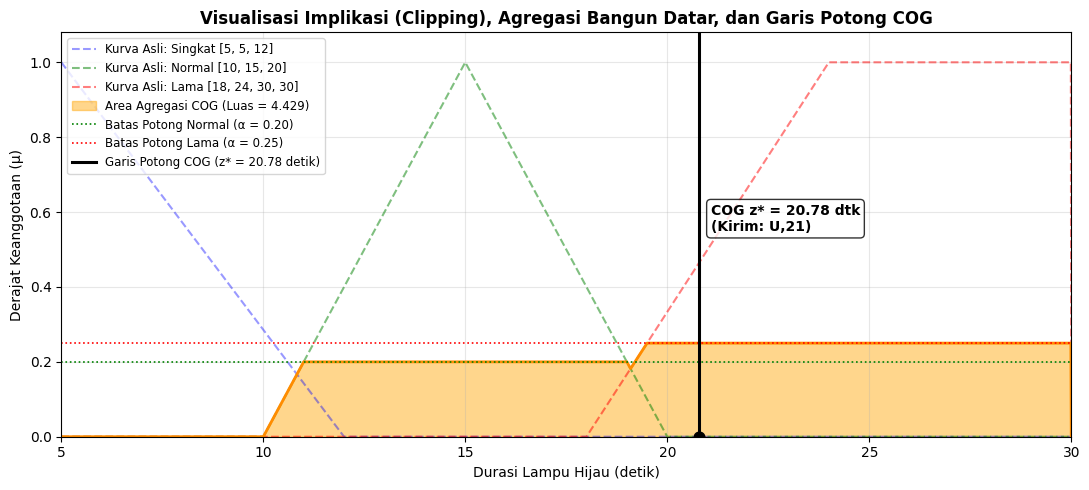

In [ ]:
import matplotlib.pyplot as plt

# ==============================================================================
# BAGIAN 1: FUNGSI KEANGGOTAAN PROSEDURAL (TANPA LIBRARY)
# ==============================================================================
def mf_trapesium(x, a, b, c, d):
    """Menghitung derajat keanggotaan kurva trapesium [a, b, c, d]."""
    if x <= a or x >= d:
        if (a == b and x == a) or (c == d and x == d):
            return 1.0
        return 0.0
    elif b <= x <= c:
        return 1.0
    elif a < x < b:
        return (x - a) / (b - a)
    elif c < x < d:
        return (d - x) / (d - c)
    return 0.0

def mf_segitiga(x, a, b, c):
    """Menghitung derajat keanggotaan kurva segitiga [a, b, c]."""
    if x <= a or x >= c:
        if (a == b and x == a) or (b == c and x == c):
            return 1.0
        return 0.0
    elif x == b:
        return 1.0
    elif a < x < b:
        return (x - a) / (b - a)
    elif b < x < c:
        return (c - x) / (c - b)
    return 0.0

def hitung_fuzzifikasi_input(nilai):
    """Mengembalikan kamus derajat keanggotaan untuk nilai kepadatan (0 - 100%)."""
    return {
        "Sepi"  : mf_trapesium(nilai, 0.0, 0.0, 15.0, 35.0),
        "Sedang": mf_segitiga(nilai, 25.0, 50.0, 75.0),
        "Padat" : mf_trapesium(nilai, 65.0, 85.0, 100.0, 100.0)
    }

def hitung_mf_output(z, himpunan):
    """Mengembalikan nilai kurva asli output Durasi_Hijau sebelum dipotong."""
    if himpunan == "Singkat":
        return mf_segitiga(z, 5.0, 5.0, 12.0)
    elif himpunan == "Normal":
        return mf_segitiga(z, 10.0, 15.0, 20.0)
    elif himpunan == "Lama":
        return mf_trapesium(z, 18.0, 24.0, 30.0, 30.0)
    return 0.0


# ==============================================================================
# BAGIAN 2: SIMULASI SENSORIK KAMERA, LUX, KECEPATAN & JUMLAH KENDARAAN
# ==============================================================================
def simulasi_sensor_persimpangan():
    """
    Simulasi matriks piksel 2D prosedural untuk:
    - Kalibrasi Lux (kecerahan rata-rata aspal kosong)
    - Background Subtraction pada 4 ROI (masing-masing 100 x 120 = 12.000 piksel)
    - Estimasi jumlah kendaraan & kecepatan rata-rata
    """
    # Representasi intensitas piksel grayscale (0 - 255)
    intensitas_aspal_kosong = 65  # Setara kondisi siang cerah berawan
    estimasi_lux = (intensitas_aspal_kosong / 255.0) * 1000.0  # Konversi skala lux
    threshold_adaptif = 30 if estimasi_lux > 200 else 18

    # Data simulasi piksel terdeteksi pada tiap ROI (Luas tiap ROI = 12.000 piksel)
    luas_roi = 12000
    luas_rata_rata_1_mobil = 1200  # 1 mobil = 1.200 piksel pada sudut pandang bird's-eye

    data_roi = {
        "Utara"  : {"piksel_objek": 8400, "geser_piksel_per_detik": 15.0}, # 70.0%
        "Timur"  : {"piksel_objek": 3600, "geser_piksel_per_detik": 45.0}, # 30.0%
        "Selatan": {"piksel_objek": 1800, "geser_piksel_per_detik": 60.0}, # 15.0%
        "Barat"  : {"piksel_objek": 2400, "geser_piksel_per_detik": 55.0}  # 20.0%
    }

    skala_meter_per_piksel = 0.15  # 1 piksel = 15 cm di lapangan
    hasil_sensor = {}

    for jalur, info in data_roi.items():
        kepadatan_pct = (info["piksel_objek"] / luas_roi) * 100.0
        jumlah_mobil  = round(info["piksel_objek"] / luas_rata_rata_1_mobil)
        kecepatan_ms  = info["geser_piksel_per_detik"] * skala_meter_per_piksel
        kecepatan_kmh = kecepatan_ms * 3.6

        hasil_sensor[jalur] = {
            "total_px"   : luas_roi,
            "objek_px"   : info["piksel_objek"],
            "kepadatan"  : kepadatan_pct,
            "jumlah_unit": jumlah_mobil,
            "kecepatan"  : kecepatan_kmh
        }

    return estimasi_lux, threshold_adaptif, hasil_sensor


# ==============================================================================
# BAGIAN 3: EKSEKUSI PROSEDURAL UTAMA (RUNTUT DARI INPUT HINGGA COG)
# ==============================================================================
print("=" * 80)
print("  SIMULASI PROSEDURAL SMART TRAFFIC LIGHT (TANPA LIBRARY FUZZY/CV)")
print("=" * 80)

# 1. Baca Data Sensorik
lux, thresh_val, data_jalur = simulasi_sensor_persimpangan()
jalur_aktif = "Utara"

print(f"\n[TAHAP 1: AKUISISI SENSORIK KAMERA & PARAMETER LINGKUNGAN]")
print(f"- Intensitas Cahaya (Lux)  : {lux:.1f} Lux (Threshold Biner Adaptif = {thresh_val})")
for j, d in data_jalur.items():
    tanda = " <-- FASE AKTIF" if j == jalur_aktif else ""
    print(f"- Jalur {j:<7}: Piksel = {d['objek_px']:>5}/{d['total_px']} | "
          f"Kepadatan = {d['kepadatan']:>5.1f}% | Est. Mobil = {d['jumlah_unit']} unit | "
          f"Kec. = {d['kecepatan']:>4.1f} km/jam{tanda}")

# Tentukan nilai x1 (Jalur Aktif) dan x2 (Maksimum Jalur Lain)
x1 = data_jalur[jalur_aktif]["kepadatan"]
x2 = max(data_jalur[j]["kepadatan"] for j in data_jalur if j != jalur_aktif)

# 2. Tahap Fuzzifikasi
mu_x1 = hitung_fuzzifikasi_input(x1)
mu_x2 = hitung_fuzzifikasi_input(x2)

print(f"\n[TAHAP 2: FUZZIFIKASI INPUT]")
print(f"- Input 1 (x1 = Kepadatan_Aktif = {x1:.1f}%):")
print(f"  * μ_Sepi(70)   = {mu_x1['Sepi']:.4f}")
print(f"  * μ_Sedang(70) = (75 - 70) / (75 - 50) = {mu_x1['Sedang']:.4f}")
print(f"  * μ_Padat(70)  = (70 - 65) / (85 - 65) = {mu_x1['Padat']:.4f}")
print(f"- Input 2 (x2 = Kepadatan_Lain  = {x2:.1f}%):")
print(f"  * μ_Sepi(30)   = (35 - 30) / (35 - 15) = {mu_x2['Sepi']:.4f}")
print(f"  * μ_Sedang(30) = (30 - 25) / (50 - 25) = {mu_x2['Sedang']:.4f}")
print(f"  * μ_Padat(30)  = {mu_x2['Padat']:.4f}")

# 3. Tahap Evaluasi Seluruh 9 Rule (Operator AND = MIN)
daftar_rules = [
    ("R1", "Sepi",   "Sepi",   "Singkat"),
    ("R2", "Sepi",   "Sedang", "Singkat"),
    ("R3", "Sepi",   "Padat",  "Singkat"),
    ("R4", "Sedang", "Sepi",   "Normal"),
    ("R5", "Sedang", "Sedang", "Normal"),
    ("R6", "Sedang", "Padat",  "Singkat"),
    ("R7", "Padat",  "Sepi",   "Lama"),
    ("R8", "Padat",  "Sedang", "Lama"),
    ("R9", "Padat",  "Padat",  "Normal"),
]

print(f"\n[TAHAP 3: EVALUASI SELURUH 9 ATURAN (OPERATOR AND = MIN)]")
print(f"{'Rule':<5} | {'IF Aktif (x1)':<15} | {'AND Lain (x2)':<15} | {'THEN Output':<10} | {'Alpha (min)':<11} | {'Status'}")
print("-" * 80)

# Simpan nilai pemotongan maksimum (Agregasi) untuk tiap himpunan output
agregasi_clip = {"Singkat": 0.0, "Normal": 0.0, "Lama": 0.0}

for kode, kond_x1, kond_x2, out_label in daftar_rules:
    val_1 = mu_x1[kond_x1]
    val_2 = mu_x2[kond_x2]
    alpha = min(val_1, val_2)  # Operator AND (MIN)
    status = "AKTIF" if alpha > 0 else "Tidak Aktif"

    if alpha > agregasi_clip[out_label]:
        agregasi_clip[out_label] = alpha

    print(f"{kode:<5} | {kond_x1:<6} ({val_1:.2f})   | {kond_x2:<6} ({val_2:.2f})   | "
          f"{out_label:<10} | {alpha:<11.4f} | {status}")

# 4. Tahap Implikasi & Agregasi
print(f"\n[TAHAP 4: IMPLIKASI (CLIPPING) & AGREGASI (MAX UNION)]")
print(f"- Tinggi pemotongan maksimal 'Singkat' : {agregasi_clip['Singkat']:.4f}")
print(f"- Tinggi pemotongan maksimal 'Normal'  : {agregasi_clip['Normal']:.4f}")
print(f"- Tinggi pemotongan maksimal 'Lama'    : {agregasi_clip['Lama']:.4f}")

# 5. Analisis Bangun Datar Perpotongan & Integrasi Numerik COG (Center of Gravity)
print(f"\n[TAHAP 5: ANALISIS BANGUN DATAR HASIL POTONGAN & DEFUZZIFIKASI COG]")
# Bangun 1: Trapesium hasil pemotongan kurva 'Normal' [10, 15, 20] pada tinggi y = 0.20
# Titik potong kiri: 10 + 0.20*(15-10) = 11.0 | Titik potong kanan: 20 - 0.20*(20-15) = 19.0
luas_bangun_1 = 0.5 * ((20.0 - 10.0) + (19.0 - 11.0)) * 0.20
titik_tengah_1 = 15.0

# Bangun 2: Trapesium hasil pemotongan kurva 'Lama' [18, 24, 30, 30] pada tinggi y = 0.25
# Titik potong kiri: 18 + 0.25*(24-18) = 19.5 | Batas kanan: 30.0
luas_bangun_2 = 0.5 * ((30.0 - 18.0) + (30.0 - 19.5)) * 0.25
titik_tengah_2 = 24.67  # Pusat geometris trapesium siku-siku [18, 19.5, 30, 30]

# Bangun 3 (Irisan/Overlap antara kurva Normal dan Lama di rentang z = 18 s/d 20):
# Pada z = 18.75 terjadi perpotongan garis turun 'Normal' dan garis naik 'Lama' dengan tinggi y = 0.125
luas_irisan = 0.5 * (20.0 - 18.0) * 0.125

print(f"- Bangun Datar 1 (Trapesium 'Normal' terpotong di y=0.20):")
print(f"  * Alas bawah = 10.0 (z=10..20), Alas atas = 8.0 (z=11..19), Tinggi = 0.20")
print(f"  * Luas Bangun 1 (A1) = 0.5 * (10 + 8) * 0.20 = {luas_bangun_1:.4f}")
print(f"- Bangun Datar 2 (Trapesium 'Lama' terpotong di y=0.25):")
print(f"  * Alas bawah = 12.0 (z=18..30), Alas atas = 10.5 (z=19.5..30), Tinggi = 0.25")
print(f"  * Luas Bangun 2 (A2) = 0.5 * (12 + 10.5) * 0.25 = {luas_bangun_2:.4f}")
print(f"- Bangun Datar 3 (Segitiga Irisan Overlap di z=18..20, puncak potong z=18.75, y=0.125):")
print(f"  * Luas Irisan (A_irisan) = 0.5 * 2.0 * 0.125 = {luas_irisan:.4f}")
print(f"- Total Luas Gabungan (A_total = A1 + A2 - A_irisan) = {luas_bangun_1 + luas_bangun_2 - luas_irisan:.4f}")

# Integrasi Numerik COG Runtut (Step dz = 0.01 detik dari z = 5.00 hingga z = 30.00)
dz = 0.01
z_sekarang = 5.0
pembilang_momen = 0.0  # Sigma (z * mu_agregasi(z) * dz)
penyebut_luas   = 0.0  # Sigma (mu_agregasi(z) * dz)

list_z = []
list_mu_singkat = []
list_mu_normal  = []
list_mu_lama    = []
list_mu_agregasi = []

while z_sekarang <= 30.0001:
    # Nilai asli tiap kurva
    y_singkat_asli = hitung_mf_output(z_sekarang, "Singkat")
    y_normal_asli  = hitung_mf_output(z_sekarang, "Normal")
    y_lama_asli    = hitung_mf_output(z_sekarang, "Lama")

    # Implikasi (Clipping dengan nilai alpha masing-masing)
    y_singkat_potong = min(agregasi_clip["Singkat"], y_singkat_asli)
    y_normal_potong  = min(agregasi_clip["Normal"],  y_normal_asli)
    y_lama_potong    = min(agregasi_clip["Lama"],    y_lama_asli)

    # Agregasi (Union / MAX)
    y_gabungan = max(y_singkat_potong, y_normal_potong, y_lama_potong)

    # Akumulasi momen dan luas pias
    luas_pias = y_gabungan * dz
    pembilang_momen += z_sekarang * luas_pias
    penyebut_luas   += luas_pias

    # Simpan untuk grafik
    list_z.append(z_sekarang)
    list_mu_singkat.append(y_singkat_asli)
    list_mu_normal.append(y_normal_asli)
    list_mu_lama.append(y_lama_asli)
    list_mu_agregasi.append(y_gabungan)

    z_sekarang += dz

z_cog = pembilang_momen / penyebut_luas
durasi_final = round(z_cog)

print(f"\n[TAHAP 6: HASIL AKHIR DEFUZZIFIKASI & AKTUASI SERIAL]")
print(f"- Pembilang Momen (∫ z · μ(z) dz) = {pembilang_momen:.4f}")
print(f"- Penyebut Luas   (∫ μ(z) dz)     = {penyebut_luas:.4f}")
print(f"- Titik Pusat COG (z*)            = {pembilang_momen:.4f} / {penyebut_luas:.4f} = {z_cog:.2f} detik")
print(f"- Pembulatan ke Mikrokontroler    = {durasi_final} detik (Paket Serial: 'U,{durasi_final}\\n')")
print("=" * 80)


# ==============================================================================
# BAGIAN 4: VISUALISASI GRAFIK PEMOTONGAN BANGUN DATAR & GARIS POTONG COG
# ==============================================================================
plt.figure(figsize=(11, 5))

# Plot kurva asli (garis putus-putus)
plt.plot(list_z, list_mu_singkat, 'b--', alpha=0.4, label='Kurva Asli: Singkat [5, 5, 12]')
plt.plot(list_z, list_mu_normal,  'g--', alpha=0.5, label='Kurva Asli: Normal [10, 15, 20]')
plt.plot(list_z, list_mu_lama,    'r--', alpha=0.5, label='Kurva Asli: Lama [18, 24, 30, 30]')

# Arsiran bangun datar hasil implikasi & agregasi
plt.fill_between(list_z, 0, list_mu_agregasi, color='orange', alpha=0.45,
                 label=f'Area Agregasi COG (Luas = {penyebut_luas:.3f})')
plt.plot(list_z, list_mu_agregasi, color='darkorange', linewidth=2)

# Garis horizontal pemotongan (Implikasi Alpha)
plt.axhline(agregasi_clip["Normal"], color='green', linestyle=':', linewidth=1.2,
            label=f'Batas Potong Normal (α = {agregasi_clip["Normal"]:.2f})')
plt.axhline(agregasi_clip["Lama"], color='red', linestyle=':', linewidth=1.2,
            label=f'Batas Potong Lama (α = {agregasi_clip["Lama"]:.2f})')

# Penunjuk Garis Potong Vertikal Center of Gravity (COG / Centroid)
plt.axvline(z_cog, color='black', linestyle='-', linewidth=2.2,
            label=f'Garis Potong COG (z* = {z_cog:.2f} detik)')
plt.scatter([z_cog], [0], color='black', zorder=5, s=60)
plt.text(z_cog + 0.3, 0.55, f'COG z* = {z_cog:.2f} dtk\n(Kirim: U,{durasi_final})',
         fontsize=10, fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.title("Visualisasi Implikasi (Clipping), Agregasi Bangun Datar, dan Garis Potong COG", fontsize=12, fontweight='bold')
plt.xlabel("Durasi Lampu Hijau (detik)", fontsize=10)
plt.ylabel("Derajat Keanggotaan (μ)", fontsize=10)
plt.xlim(5, 30)
plt.ylim(0, 1.08)
plt.legend(loc='upper left', fontsize=8.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()